<a href="https://colab.research.google.com/github/brucewxyne/spark-commerce-analytics/blob/main/bullshit_with_extra_steps.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pyspark -q

from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.window import Window
from pyspark.sql.types import *

import matplotlib.pyplot as plt
import pandas as pd

spark = SparkSession.builder \
    .appName("EcommerceSalesAnalytics") \
    .getOrCreate()

print("Spark Session Created Successfully!")

Spark Session Created Successfully!


In [ ]:
from google.colab import files
import os
import zipfile

uploaded = files.upload()

zip_name = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall("/content/ecommerce_project")

print("Dataset Extracted Successfully!")

Saving cleaned_ecommerce_dataset.zip to cleaned_ecommerce_dataset.zip
Dataset Extracted Successfully!


In [ ]:
csv_files = []

for root, dirs, filenames in os.walk("/content/ecommerce_project"):
    for filename in filenames:
        if filename.endswith(".csv"):
            csv_files.append(os.path.join(root, filename))

print(csv_files)

df = spark.read.csv(
    csv_files[0],
    header=True,
    inferSchema=True
)

print("Dataset Loaded Successfully!")
df.show(10)

['/content/ecommerce_project/part-00000-6fe097a7-a4ba-46bc-86fd-c6bb89a395f1-c000.csv']
Dataset Loaded Successfully!
+--------+----------+------------+----------------+-------+--------+---------+--------------+------+------------+--------------------+
|order_id|order_date|product_name|product_category|  price|quantity|     city|payment_method|rating|total_amount|order_value_category|
+--------+----------+------------+----------------+-------+--------+---------+--------------+------+------------+--------------------+
| ORD0013|2026-07-24|      Jacket|        Clothing|6001.41|     4.0|    DELHI|   CREDIT CARD|   2.0|    24005.64|                High|
| ORD0148|2026-06-18|  Headphones|     Electronics|4732.43|     2.0|     PUNE|   NET BANKING|   1.0|     9464.86|                High|
| ORD0176|2026-07-25|       Novel|           Books| 2022.2|     5.0|HYDERABAD|           UPI|   4.0|     10111.0|                High|
| ORD0196|2026-04-10|       Jeans|        Clothing| 2544.8|     4.0|    D

In [ ]:
print("Total Rows:", df.count())
print("Total Columns:", len(df.columns))

print("Dataset Schema:")
df.printSchema()

print("Dataset Preview:")
df.show(10, truncate=False)

print("Column Names:")
print(df.columns)

Total Rows: 477
Total Columns: 11
Dataset Schema:
root
 |-- order_id: string (nullable = true)
 |-- order_date: date (nullable = true)
 |-- product_name: string (nullable = true)
 |-- product_category: string (nullable = true)
 |-- price: double (nullable = true)
 |-- quantity: double (nullable = true)
 |-- city: string (nullable = true)
 |-- payment_method: string (nullable = true)
 |-- rating: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- order_value_category: string (nullable = true)

Dataset Preview:
+--------+----------+------------+----------------+-------+--------+---------+--------------+------+------------+--------------------+
|order_id|order_date|product_name|product_category|price  |quantity|city     |payment_method|rating|total_amount|order_value_category|
+--------+----------+------------+----------------+-------+--------+---------+--------------+------+------------+--------------------+
|ORD0013 |2026-07-24|Jacket      |Clothing        |6001.4

In [ ]:
print("Missing Values:")

missing_values = df.select([
    count(
        when(
            col(c).isNull() |
            (isnan(col(c)) if dict(df.dtypes)[c] in ["double", "float"] else lit(False)),
            c
        )
    ).alias(c)
    for c in df.columns
])

missing_values.show()

print("Duplicate Records:")

total_records = df.count()
unique_records = df.dropDuplicates().count()

print("Total Records:", total_records)
print("Unique Records:", unique_records)
print("Duplicate Records:", total_records - unique_records)

Missing Values:
+--------+----------+------------+----------------+-----+--------+----+--------------+------+------------+--------------------+
|order_id|order_date|product_name|product_category|price|quantity|city|payment_method|rating|total_amount|order_value_category|
+--------+----------+------------+----------------+-----+--------+----+--------------+------+------------+--------------------+
|       0|         0|           0|               0|    0|       0|   0|             0|     0|           0|                   0|
+--------+----------+------------+----------------+-----+--------+----+--------------+------+------------+--------------------+

Duplicate Records:
Total Records: 477
Unique Records: 477
Duplicate Records: 0


In [ ]:
df = df.dropDuplicates()

# Replace missing text values
text_columns = [
    f.name for f in df.schema.fields
    if isinstance(f.dataType, StringType)
]

df = df.fillna("Unknown", subset=text_columns)

# Replace missing numeric values with median
numeric_columns = [
    f.name for f in df.schema.fields
    if isinstance(f.dataType, (IntegerType, LongType, FloatType, DoubleType))
]

for c in numeric_columns:
    median = df.approxQuantile(c, [0.5], 0.01)
    if median:
        df = df.fillna({c: median[0]})

# Remove invalid records
df = df.filter(
    (col("price") > 0) &
    (col("quantity") > 0) &
    (col("rating").between(1, 5))
)

print("Data Cleaning Completed!")
print("Remaining Records:", df.count())
df.show(5)

Data Cleaning Completed!
Remaining Records: 477
+--------+----------+------------+----------------+-------+--------+---------+--------------+------+------------------+--------------------+
|order_id|order_date|product_name|product_category|  price|quantity|     city|payment_method|rating|      total_amount|order_value_category|
+--------+----------+------------+----------------+-------+--------+---------+--------------+------+------------------+--------------------+
| ORD0390|2026-08-01|  Power Bank|     Electronics|4102.22|     5.0|BENGALURU|          CASH|   1.0|20511.100000000002|                High|
| ORD0459|2026-03-17|   Sunscreen|          Beauty|  988.9|     2.0|HYDERABAD|   NET BANKING|   5.0|            1977.8|              Medium|
| ORD0314|2026-03-18|     T-Shirt|        Clothing|7352.59|     5.0|     PUNE|   CREDIT CARD|   5.0|          36762.95|                High|
| ORD0439|2026-04-18|    Keyboard|     Electronics|3628.38|     3.0|     PUNE|           UPI|   3.0|      

In [ ]:
df = df.withColumn(
    "total_amount",
    col("price") * col("quantity")
)

df = df.withColumn(
    "order_date",
    to_date(col("order_date"))
)

df = df.withColumn(
    "sales_month",
    date_format(col("order_date"), "yyyy-MM")
)

df = df.withColumn(
    "order_value_category",
    when(col("total_amount") < 500, "Low")
    .when(col("total_amount") < 2000, "Medium")
    .otherwise("High")
)

df = df.withColumn("city", upper(trim(col("city"))))
df = df.withColumn("payment_method", upper(trim(col("payment_method"))))

print("Data Transformation Completed!")
df.show(10)

Data Transformation Completed!
+--------+----------+--------------------+----------------+-------+--------+---------+--------------+------+------------------+--------------------+-----------+
|order_id|order_date|        product_name|product_category|  price|quantity|     city|payment_method|rating|      total_amount|order_value_category|sales_month|
+--------+----------+--------------------+----------------+-------+--------+---------+--------------+------+------------------+--------------------+-----------+
| ORD0390|2026-08-01|          Power Bank|     Electronics|4102.22|     5.0|BENGALURU|          CASH|   1.0|20511.100000000002|                High|    2026-08|
| ORD0459|2026-03-17|           Sunscreen|          Beauty|  988.9|     2.0|HYDERABAD|   NET BANKING|   5.0|            1977.8|              Medium|    2026-03|
| ORD0314|2026-03-18|             T-Shirt|        Clothing|7352.59|     5.0|     PUNE|   CREDIT CARD|   5.0|          36762.95|                High|    2026-03|
| O

In [ ]:
df.createOrReplaceTempView("ecommerce_sales")

print("Spark SQL View Created Successfully!")

Spark SQL View Created Successfully!


In [ ]:
top_products = spark.sql("""
SELECT product_name,
       SUM(quantity) AS units_sold,
       SUM(total_amount) AS total_revenue
FROM ecommerce_sales
GROUP BY product_name
ORDER BY units_sold DESC
LIMIT 10
""")

print("Top 10 Selling Products:")
top_products.show(truncate=False)

Top 10 Selling Products:
+------------+----------+------------------+
|product_name|units_sold|total_revenue     |
+------------+----------+------------------+
|Headphones  |110.0     |455187.24         |
|Desk Lamp   |95.0      |437588.87         |
|Cookware Set|85.0      |325734.49000000005|
|Novel       |78.0      |230252.92         |
|Jeans       |77.0      |303693.2199999999 |
|Power Bank  |75.0      |372322.24         |
|Water Bottle|75.0      |332500.34         |
|Moisturizer |74.0      |239615.51000000004|
|Face Wash   |74.0      |325544.8          |
|Shampoo     |74.0      |318526.2100000001 |
+------------+----------+------------------+



In [ ]:
category_revenue = spark.sql("""
SELECT product_category,
       SUM(total_amount) AS total_revenue,
       SUM(quantity) AS total_units_sold
FROM ecommerce_sales
GROUP BY product_category
ORDER BY total_revenue DESC
""")

print("Revenue by Product Category:")
category_revenue.show(truncate=False)

Revenue by Product Category:
+----------------+------------------+----------------+
|product_category|total_revenue     |total_units_sold|
+----------------+------------------+----------------+
|Electronics     |1389974.3100000003|321.0           |
|Home & Kitchen  |1297215.5700000003|303.0           |
|Books           |1069997.8         |267.0           |
|Clothing        |1065185.2300000002|268.0           |
|Beauty          |1039932.1000000001|276.0           |
+----------------+------------------+----------------+



In [ ]:
city_revenue = spark.sql("""
SELECT city,
       SUM(total_amount) AS total_revenue,
       COUNT(*) AS total_orders
FROM ecommerce_sales
GROUP BY city
ORDER BY total_revenue DESC
""")

print("Revenue by City:")
city_revenue.show(truncate=False)

Revenue by City:
+---------+------------------+------------+
|city     |total_revenue     |total_orders|
+---------+------------------+------------+
|CHENNAI  |1292632.65        |92          |
|MUMBAI   |1023509.8899999999|85          |
|PUNE     |984686.67         |81          |
|BENGALURU|896193.44         |73          |
|HYDERABAD|888878.3300000001 |79          |
|DELHI    |705810.7800000001 |63          |
|UNKNOWN  |70593.25          |4           |
+---------+------------------+------------+



In [ ]:
payment_analysis = spark.sql("""
SELECT payment_method,
       COUNT(*) AS total_orders,
       SUM(total_amount) AS total_revenue
FROM ecommerce_sales
GROUP BY payment_method
ORDER BY total_revenue DESC
""")

print("Revenue by Payment Method:")
payment_analysis.show(truncate=False)

Revenue by Payment Method:
+--------------+------------+------------------+
|payment_method|total_orders|total_revenue     |
+--------------+------------+------------------+
|DEBIT CARD    |110         |1250966.1700000002|
|NET BANKING   |104         |1192368.6500000006|
|CASH          |80          |1113552.27        |
|CREDIT CARD   |95          |1112811.02        |
|UPI           |83          |1104537.5899999996|
|UNKNOWN       |5           |88069.31          |
+--------------+------------+------------------+



In [ ]:
monthly_sales = spark.sql("""
SELECT sales_month,
       SUM(total_amount) AS monthly_revenue,
       COUNT(*) AS total_orders
FROM ecommerce_sales
WHERE sales_month IS NOT NULL
GROUP BY sales_month
ORDER BY sales_month
""")

print("Monthly Sales Trends:")
monthly_sales.show(truncate=False)

Monthly Sales Trends:
+-----------+------------------+------------+
|sales_month|monthly_revenue   |total_orders|
+-----------+------------------+------------+
|2026-01    |654728.89         |53          |
|2026-02    |558483.8899999999 |50          |
|2026-03    |739984.0399999999 |54          |
|2026-04    |531812.53         |42          |
|2026-05    |699986.06         |57          |
|2026-06    |698807.8999999999 |63          |
|2026-07    |687109.7699999998 |53          |
|2026-08    |776074.02         |64          |
|2026-09    |515317.91000000003|41          |
+-----------+------------------+------------+



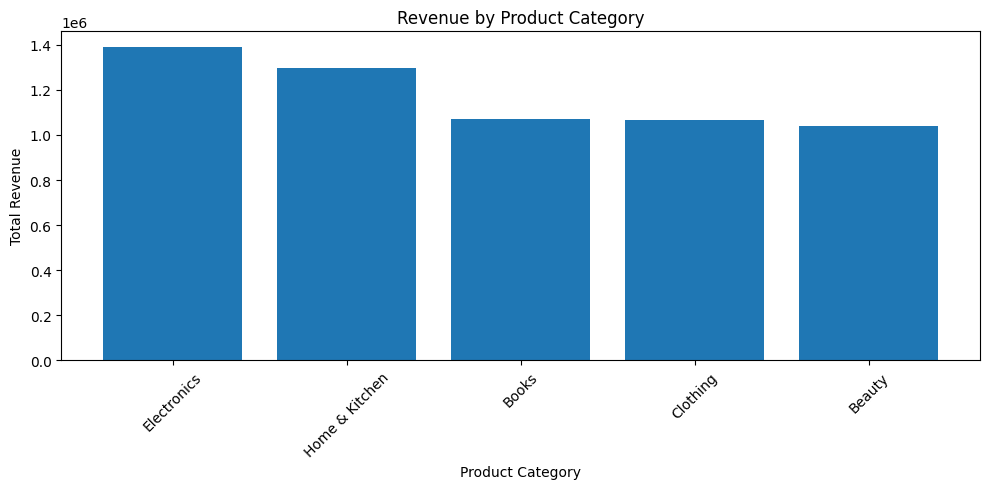

In [ ]:
category_pd = category_revenue.toPandas()

plt.figure(figsize=(10, 5))
plt.bar(
    category_pd["product_category"],
    category_pd["total_revenue"]
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

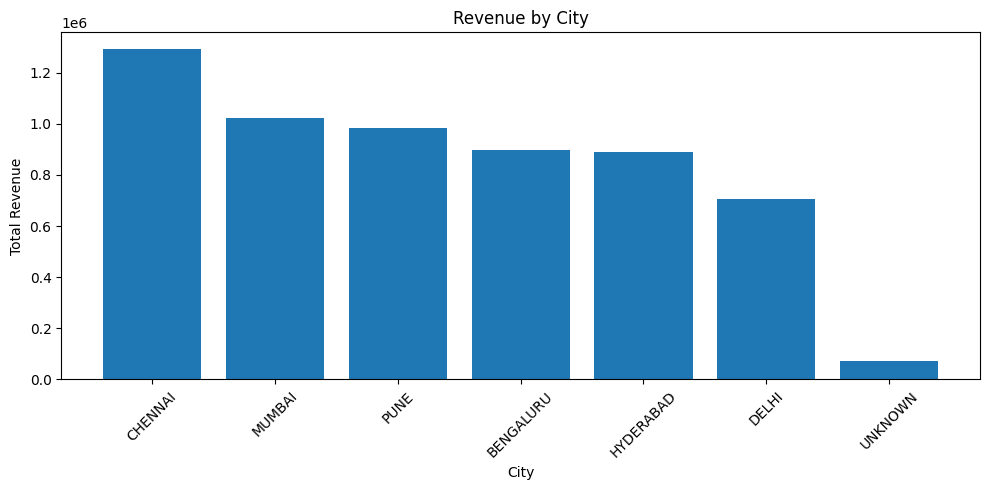

In [ ]:
city_pd = city_revenue.toPandas()

plt.figure(figsize=(10, 5))
plt.bar(city_pd["city"], city_pd["total_revenue"])

plt.title("Revenue by City")
plt.xlabel("City")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

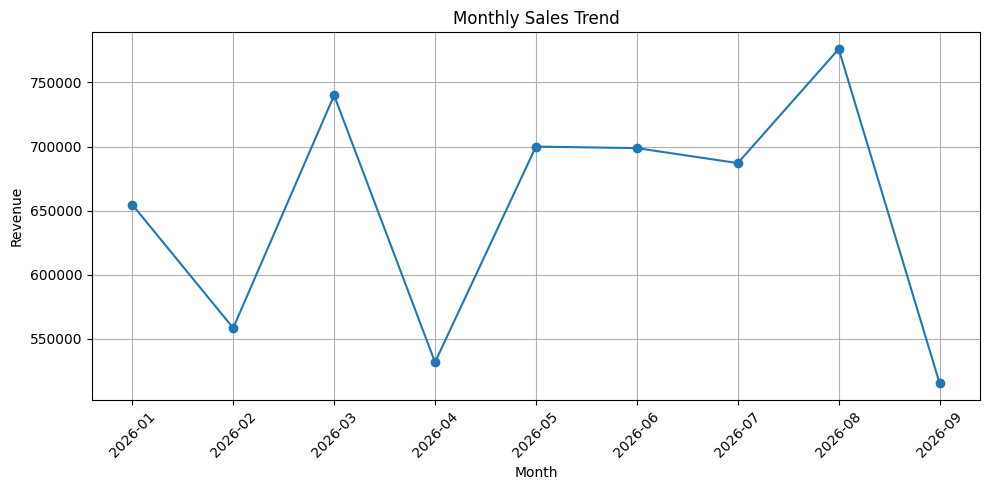

In [ ]:
print("BUSINESS INSIGHTS")

print("\n1. Top Selling Products:")
top_products.show(3, truncate=False)

print("\n2. Highest Revenue Category:")
category_revenue.show(1, truncate=False)

print("\n3. Highest Revenue City:")
city_revenue.show(1, truncate=False)

print("\n4. Most Used Payment Method:")
payment_analysis.orderBy(
    col("total_orders").desc()
).show(1, truncate=False)

print("\n5. Highest Revenue Month:")
monthly_sales.orderBy(
    col("monthly_revenue").desc()
).show(1, truncate=False)

BUSINESS INSIGHTS

1. Top Selling Products:
+------------+----------+------------------+
|product_name|units_sold|total_revenue     |
+------------+----------+------------------+
|Headphones  |110.0     |455187.24         |
|Desk Lamp   |95.0      |437588.87         |
|Cookware Set|85.0      |325734.49000000005|
+------------+----------+------------------+
only showing top 3 rows

2. Highest Revenue Category:
+----------------+------------------+----------------+
|product_category|total_revenue     |total_units_sold|
+----------------+------------------+----------------+
|Electronics     |1389974.3100000003|321.0           |
+----------------+------------------+----------------+
only showing top 1 row

3. Highest Revenue City:
+-------+-------------+------------+
|city   |total_revenue|total_orders|
+-------+-------------+------------+
|CHENNAI|1292632.65   |92          |
+-------+-------------+------------+
only showing top 1 row

4. Most Used Payment Method:
+--------------+---------

In [ ]:
print("BUSINESS RECOMMENDATIONS")

print("1. Maintain sufficient stock of top-selling products.")

print("2. Focus marketing campaigns on high-revenue product categories.")

print("3. Improve promotional strategies in cities generating lower revenue.")

print("4. Monitor customer payment preferences and provide convenient payment options.")

print("5. Use monthly sales trends to plan inventory and marketing activities.")

BUSINESS RECOMMENDATIONS
1. Maintain sufficient stock of top-selling products.
2. Focus marketing campaigns on high-revenue product categories.
3. Improve promotional strategies in cities generating lower revenue.
4. Monitor customer payment preferences and provide convenient payment options.
5. Use monthly sales trends to plan inventory and marketing activities.


In [ ]:
output_folder = "/content/ecommerce_project_results"

os.makedirs(output_folder, exist_ok=True)

top_products.coalesce(1).write.mode("overwrite").option(
    "header", True
).csv(output_folder + "/top_products")

category_revenue.coalesce(1).write.mode("overwrite").option(
    "header", True
).csv(output_folder + "/category_revenue")

city_revenue.coalesce(1).write.mode("overwrite").option(
    "header", True
).csv(output_folder + "/city_revenue")

payment_analysis.coalesce(1).write.mode("overwrite").option(
    "header", True
).csv(output_folder + "/payment_analysis")

monthly_sales.coalesce(1).write.mode("overwrite").option(
    "header", True
).csv(output_folder + "/monthly_sales")

print("All Analytical Results Exported Successfully!")

All Analytical Results Exported Successfully!


In [ ]:
import shutil

shutil.make_archive(
    "/content/ecommerce_project_results",
    "zip",
    output_folder
)

files.download("/content/ecommerce_project_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>